In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy.ma as ma
import pandas as pd 
import skimage as sk
import scipy.ndimage as nd
from ROOT import TProfile, TGraphErrors, TH2F, TLegend
# import ROOT

import sys
import os
## ===== Así se importan las funciones de arhcivos en otras direcciones === ###
module_path = os.path.abspath('../functions') # Adjust relative path as needed
# # Or use an absolute path: module_path = '/home/your_user/projects/utils'

if module_path not in sys.path:
    sys.path.append(module_path)

from functionsNEW import *
# from MCM_Analysis.functions import *

def gaussian(x, a, mean, sigma):
    return a * np.exp(-((x - mean)**2 / (2 * sigma**2)))

# def Gaussian2(x,m1,s1,g1,a1, m2, s2, g2, a2): #data, mean, sigma, gain, height1, heigth2
#     return a1*np.exp(-1/2*((x-m1-g1)/s1)**2) + a2*np.exp(-1/2*((x-m2-g2)/s2)**2)

def Gaussian2(x,m,s,g,a1,a2): #data, mean, sigma, gain, height1, heigth2
    return a1*np.exp(-1/2*((x-m)/s)**2)+a2*np.exp(-1/2*((x-m-g)/s)**2)


def EnergySpectrum(x, N):
    return N * np.sin(x)*np.cos(x)**3

# print(time.time())
# print(time.gmtime(0))

In [2]:
plt.rcParams.update({
    "image.origin": "lower",
    "image.aspect": 1,
    #"text.usetex": True,
    "grid.alpha": .5,
    "axes.linewidth": 3,
    "lines.linewidth" : 1,
    "font.size":    15.0,
    "xaxis.labellocation": 'right',  # alignment of the xaxis label: {left, right, center}
    "yaxis.labellocation": 'top',  # alignment of the yaxis label: {bottom, top, center}
    "xtick.top":           True ,  # draw ticks on the top side
    "xtick.major.size":    8    ,# major tick size in points
    "xtick.minor.size":    4      ,# minor tick size in points
    "xtick.direction":     'in',
    "xtick.minor.visible": True,
    "ytick.right":           True ,  # draw ticks on the top side
    "ytick.major.size":    8    ,# major tick size in points
    "ytick.minor.size":    4      ,# minor tick size in points
    "ytick.direction":     'in',
    "ytick.minor.visible": True,
    "ytick.major.width":   2   , # major tick width in points
    "ytick.minor.width":   1 ,
    "xtick.major.width":   2   , # major tick width in points
    "xtick.minor.width":   1 ,
    "legend.framealpha": 0 ,
    "legend.loc": 'best',

})

Colormap = 'jet'

Filename: ../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  CCD01         1 ImageHDU       174   (500, 500)   float32   
  2  CCD02         1 ImageHDU       174   (500, 500)   float32   
  3  CCD03         1 ImageHDU       174   (500, 500)   float32   
  4  CCD04         1 ImageHDU       172   (500, 500)   float32   
  5  CCD05         1 ImageHDU       174   (500, 500)   float32   
  6  CCD06         1 ImageHDU       174   (500, 500)   float32   
  7  CCD07         1 ImageHDU       172   (500, 500)   float32   
  8  CCD08         1 ImageHDU       174   (500, 500)   float32   
  9  CCD09         1 ImageHDU       172   (500, 500)   float32   
 10  CCD10         1 ImageHDU       174   (500, 500)   float32   
 11  CCD11         1 ImageHDU       172   (500, 500)   float32   
 12  CCD12         1 ImageHDU       174   (50

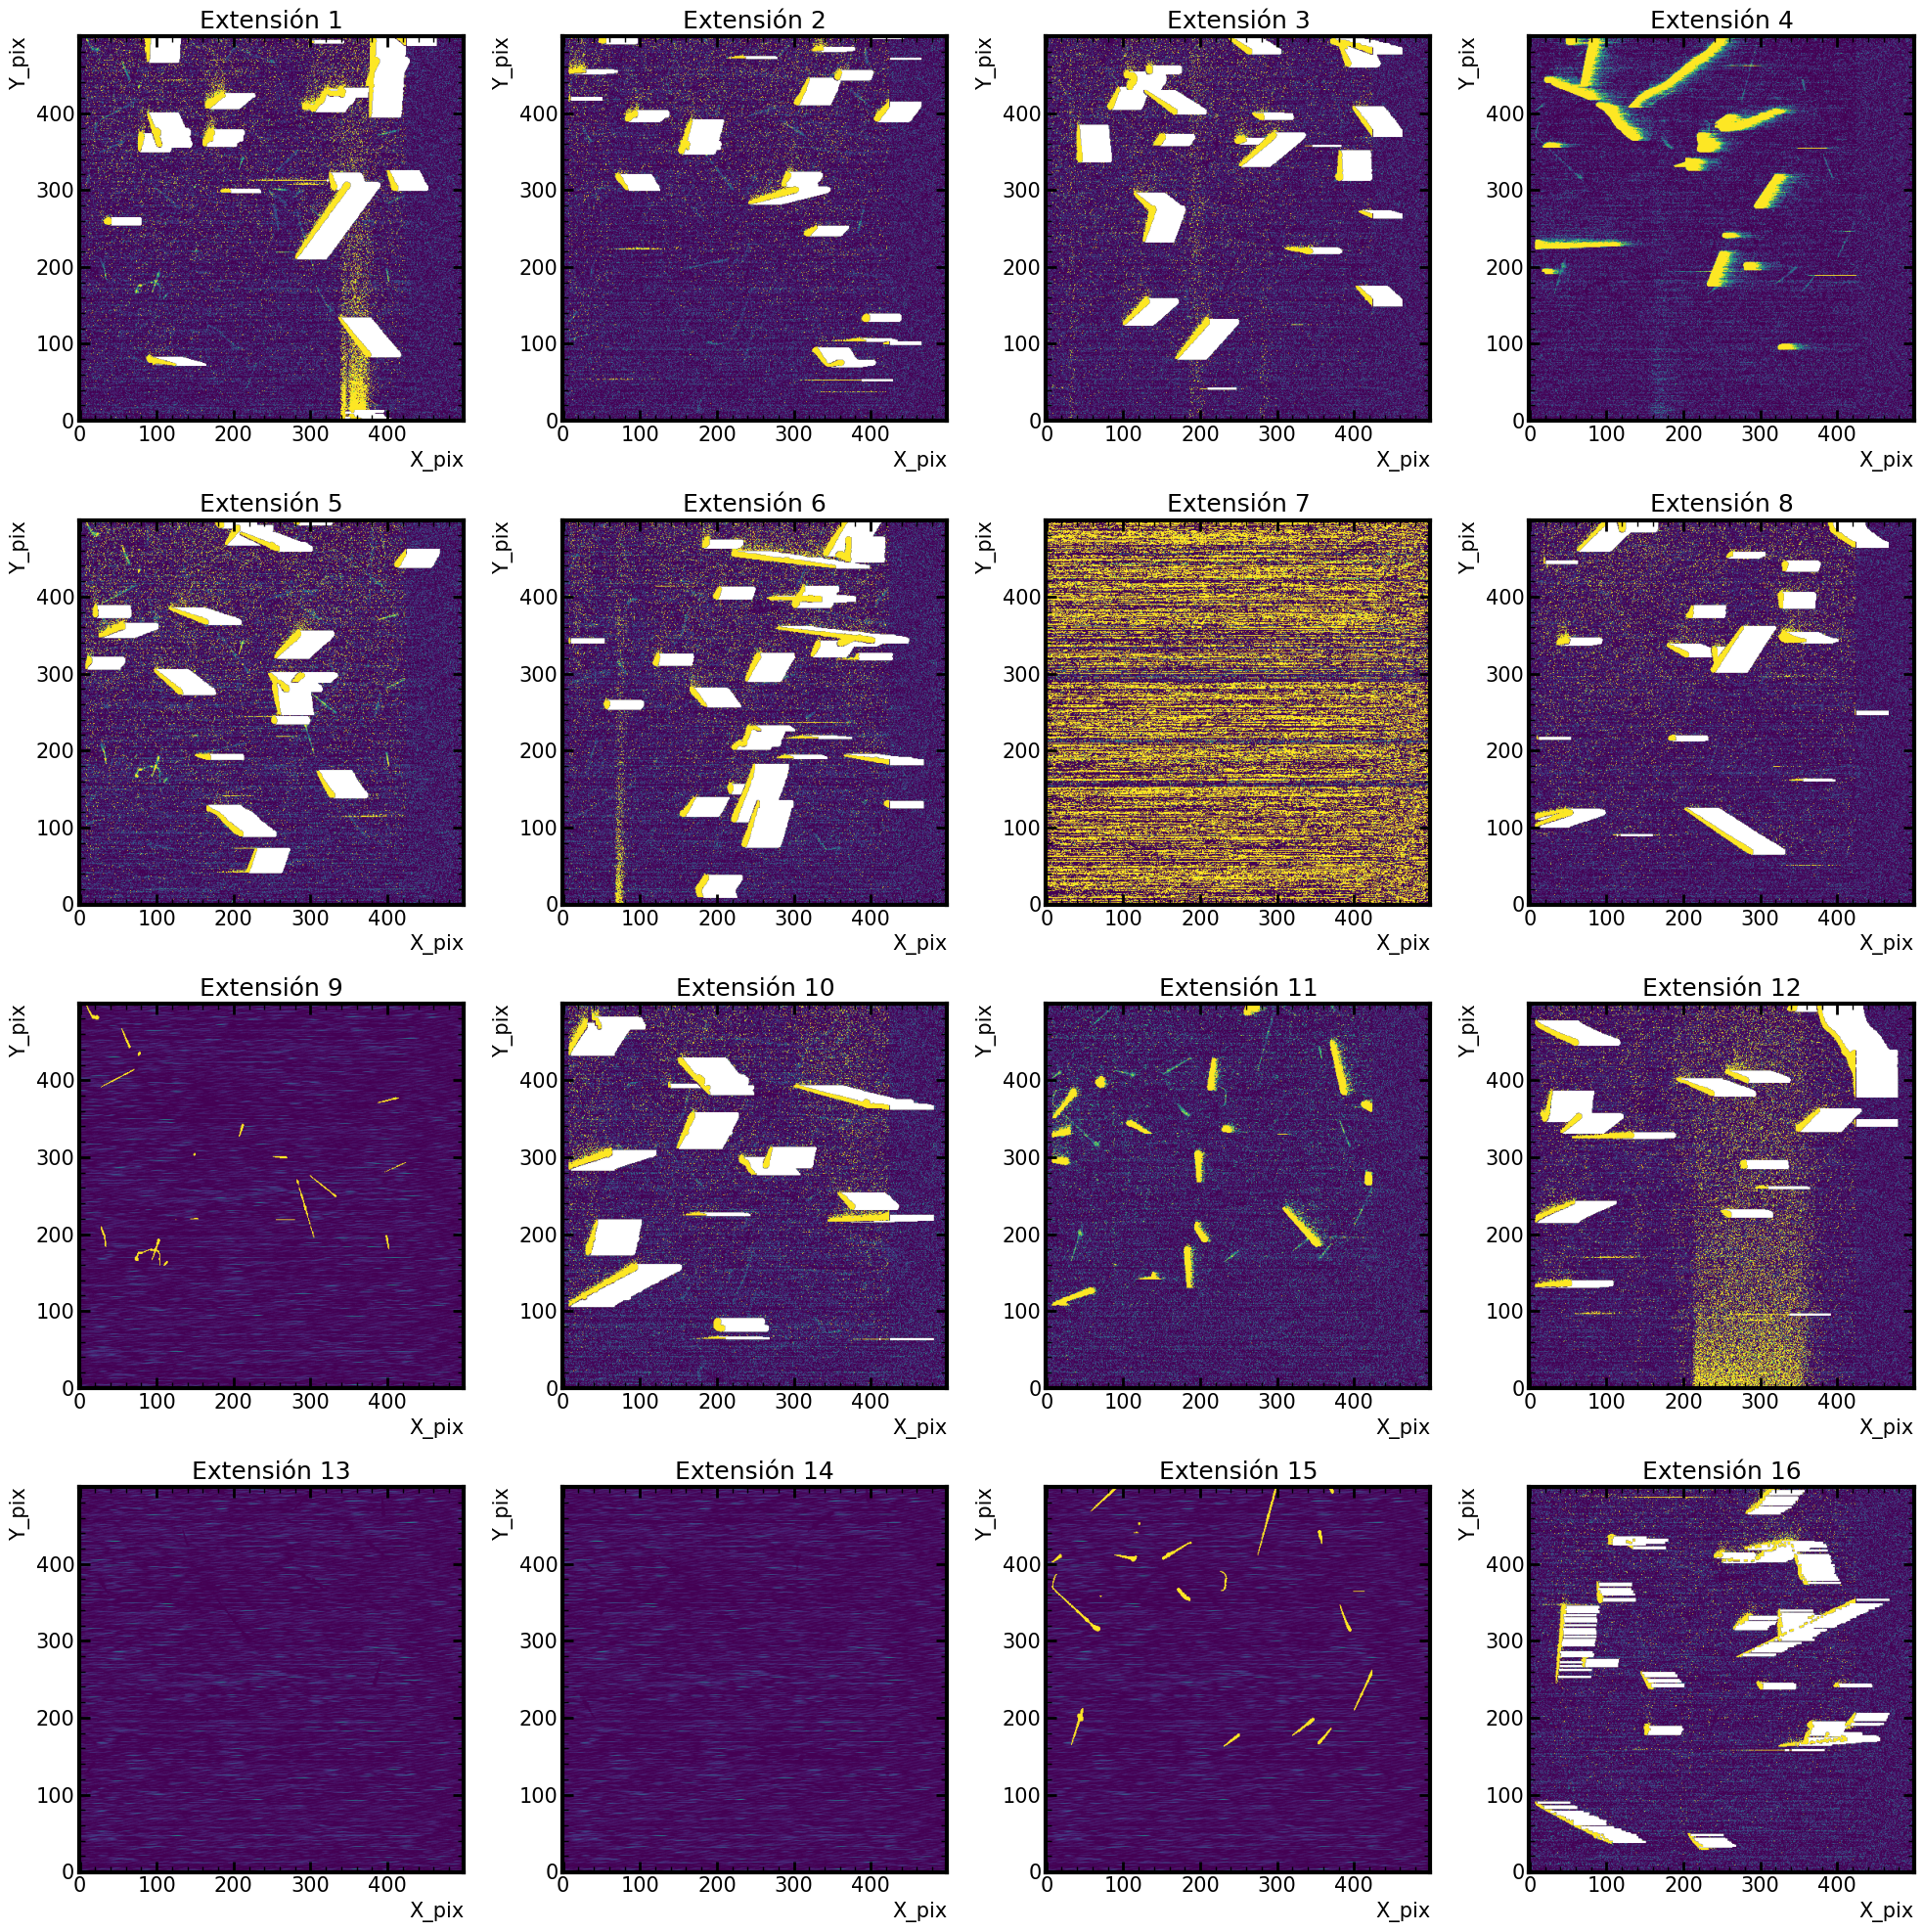

In [3]:
# path = '../../images/CONNIE_MCM/RUN_214/calib_equalized_demuxed_runID214_MCM_NROW500_ANSAMP500_EXP0_1000.fits'
path = '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits'

# path = '/home/bruce/Downloads/proc_skp_m_009_microchip_T_170_Vv82_NSAMP_324_NROW_100_NCOL_700.fits'

Colormap = 'jet'

hdu_list = fits.open(path)
print("Info: ", hdu_list.info())
print('----------------')
# hdu_list[0].header
list_gains = []
plt.figure(figsize=(20,20))
for i in range(1,17):
    plt.subplot(4,4,i)
    # plt.imshow(hdu_list[i].data-np.median(hdu_list[i].data),vmin = 10, vmax = 100, cmap = Colormap)
    plt.imshow(hdu_list[i].data,vmin = 0, vmax = 1)
    plt.title('Extensión '+str(i))
    plt.ylabel('Y_pix')
    plt.xlabel('X_pix')

    # display(hdu_list[i].header)
    list_gains.append(hdu_list[i].header["GAIN_RUN"])

    
plt.tight_layout()
plt.show()




In [4]:
# Choose an extension, write the number directly
extension = 2
x_max = 430
y_max = 500
border = 10

activeArea = hdu_list[extension].data[border:y_max-border, border:x_max] # Without the border
oScan = hdu_list[extension].data[border:y_max-border, x_max:]
header = hdu_list[extension].header

display(header)
##### Sigma en e- ####
Gain = list_gains[extension - 1] # ADU/e
Sigma = 0.18 # e- ------- This images doesn't have the sigma yet.

print(f"Gain: {Gain} ADU/e-")
print(f"Sigma: {Sigma} e-")


XTENSION= 'IMAGE   '           / Image extension                                
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                  500                                                  
NAXIS2  =                  500                                                  
PCOUNT  =                    0 / number of parameters                           
GCOUNT  =                    1 / number of groups                               
ANSAMP  = '500     '           / Smart sequencer variable                       
CCDNCOL = '2148    '           / Smart sequencer variable                       
CCDNPRES= '7       '           / Smart sequencer variable                       
CCDNROW = '2556    '           / Smart sequencer variable                       
NCOL    = '500     '           / Smart sequencer variable                       
NCOL1   = '424     '        

Gain: 706.0535554368424 ADU/e-
Sigma: 0.18 e-


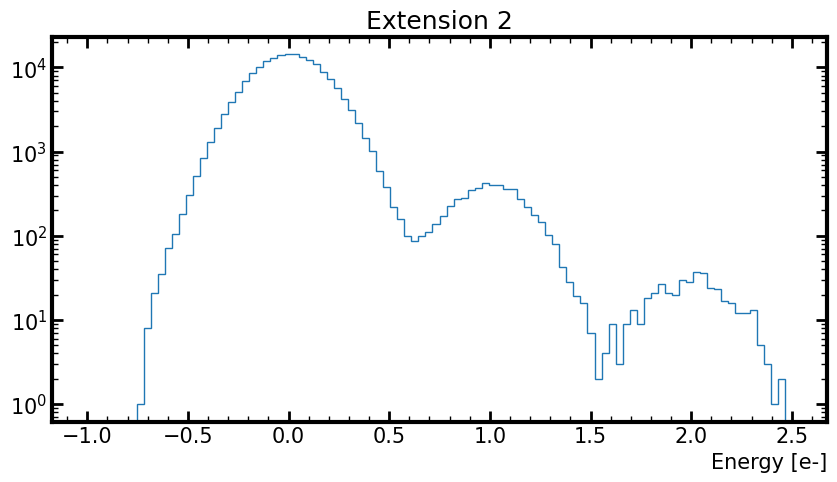

In [5]:
fig, axs = plt.subplots(figsize=[10,5])
axs.hist(activeArea.flatten(), range=(-1,2.5), bins=100, histtype="step")
# axs.hist(oScan.flatten(), range=(-1,2.5), bins=100, histtype="step")
axs.set_xlabel('Energy [e-]')
axs.set_title(f"Extension {extension}")
axs.set_yscale('log')

plt.show()

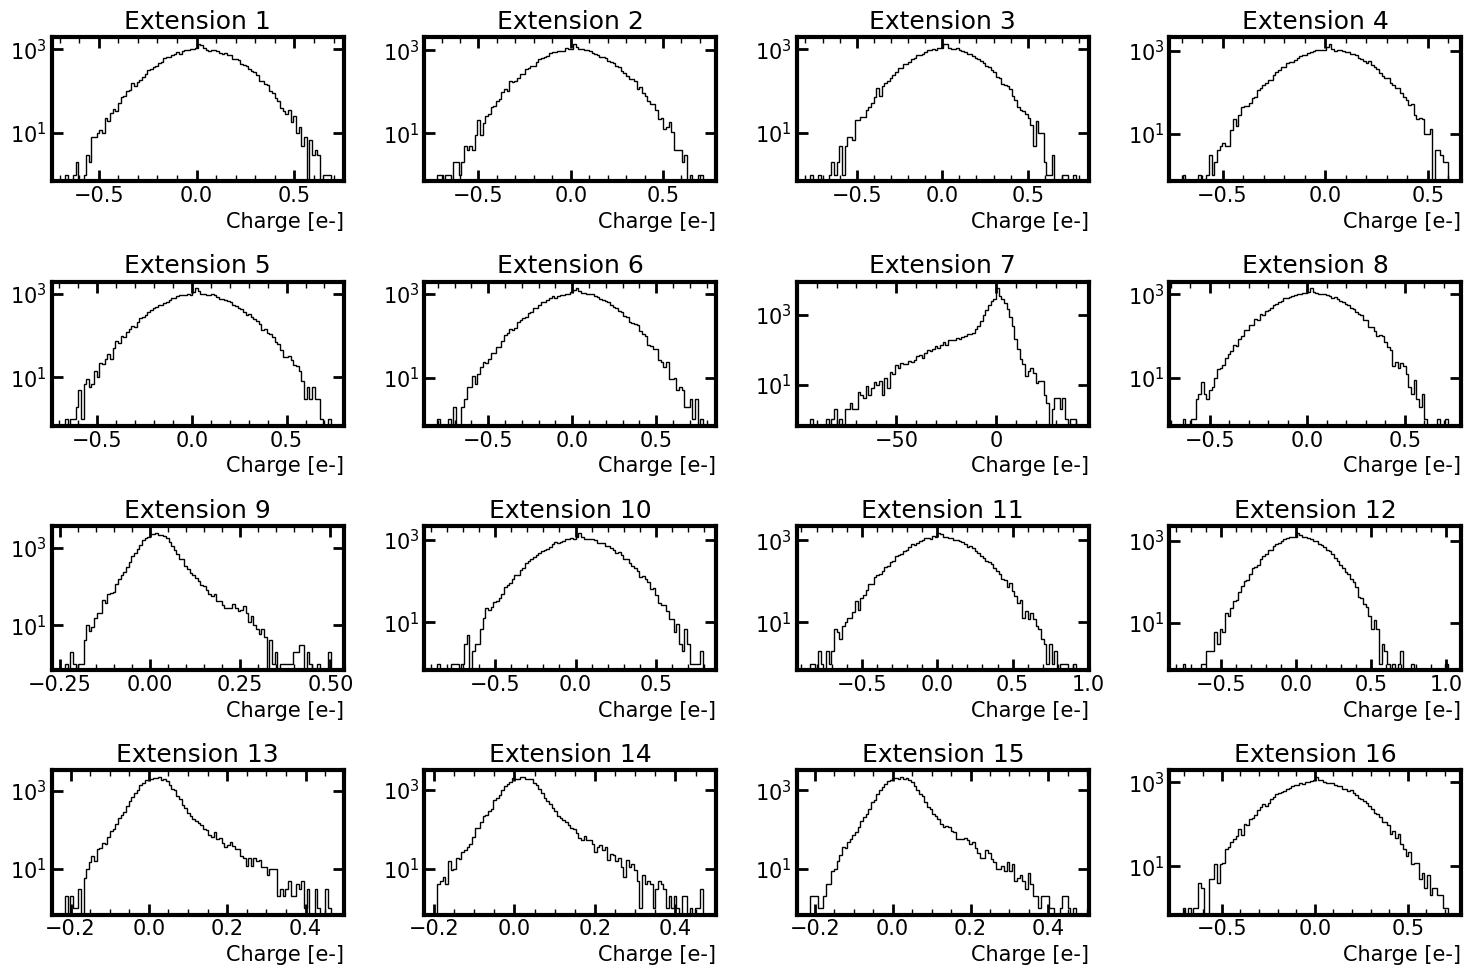

In [7]:
# print(np.max(data_muons_extension_4['charge']))
BINS = 100
plot_range = (1.3, 4)

plt.figure(figsize = [15,10])
for ext in range(1,17):
    # if ext == 9 or ext == 15:
    #     continue
    actA = hdu_list[ext].data[border:y_max-border, border:x_max-border] # Without the border
    oscan = hdu_list[ext].data[border:y_max-border, x_max:]

    plt.subplot(4,4,ext)
    # plt.hist(actA.flatten(), bins = BINS, color = 'k',  histtype = 'step')#,range= (plot_range[0], plot_range[1]))
    plt.hist(oscan.flatten(), bins = BINS, color = 'k',  histtype = 'step')#,range= (plot_range[0], plot_range[1]))
    plt.title('Extension '+str(ext))
    # axs.ylabel('Y_pix')
    plt.xlabel('Charge [e-]')

    ## Escala Log
    plt.yscale('log')

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)

plt.tight_layout()
plt.show()

## Creacción del DataFrame de los clusters detectados

In [7]:
extension = 10
activeArea = hdu_list[extension].data[border:y_max-border, border:x_max] # Without the border
oScan = hdu_list[extension].data[border:y_max-border, x_max:]
header = hdu_list[extension].header


min_energy_for_label = 10* Sigma
print(f"Threshold selected: {min_energy_for_label} e-")
label, n_events = sk.measure.label(activeArea >= min_energy_for_label, connectivity=2, return_num=True)
prop = sk.measure.regionprops(label, activeArea)

print(f"Clusters detected: {n_events}")
TotalDataFrame = event_DataFrame(dataCal=activeArea, label_img=label, nlabels_img =n_events, 
                                    prop=prop, header=header, extension=extension, unidades = 1)

TotalDataFrame

display(TotalDataFrame[TotalDataFrame["Total Charge (e-)"].between(1000,1000000)])

# [9, 14, 28, 37, 80, 81, 107, 160, 211]

Threshold selected: 1.7999999999999998 e-
Clusters detected: 282
Events: 282


,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
10,470,10,15x18,187,21130.099609,112.995003,"[6.2513, 7.8503]"
14,470,10,88x56,696,70825.281250,101.760002,"[47.8218, 29.9339]"
28,470,10,17x48,275,32161.093750,116.948997,"[8.1418, 19.7564]"
34,470,10,80x13,595,54421.000000,91.463997,"[43.7244, 4.2084]"
37,470,10,27x5,78,2022.891968,25.934999,"[13.6795, 1.0897]"
56,470,10,23x24,198,21536.144531,108.767998,"[11.7727, 11.0051]"
79,470,10,23x26,203,22364.548828,110.169998,"[9.6502, 12.266]"
80,470,10,55x28,477,45895.390625,96.217003,"[28.2285, 13.9455]"
81,470,10,13x28,174,19182.605469,110.245003,"[6.069, 12.2759]"


In [8]:
list_charge = all_cluster(dataCal=activeArea, label_img=label, nlabels_img=n_events, prop=prop)

In [9]:
print(len(list_charge))
print(f'{list_charge[0]} e-')

282
1.9889683723449707 e-


## Visualizar un cluster y su información

,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
81,470,10,13x28,174,19182.605469,110.245003,"[6.069, 12.2759]"


13
Event Slice: x: [250,263], y: [275,303]


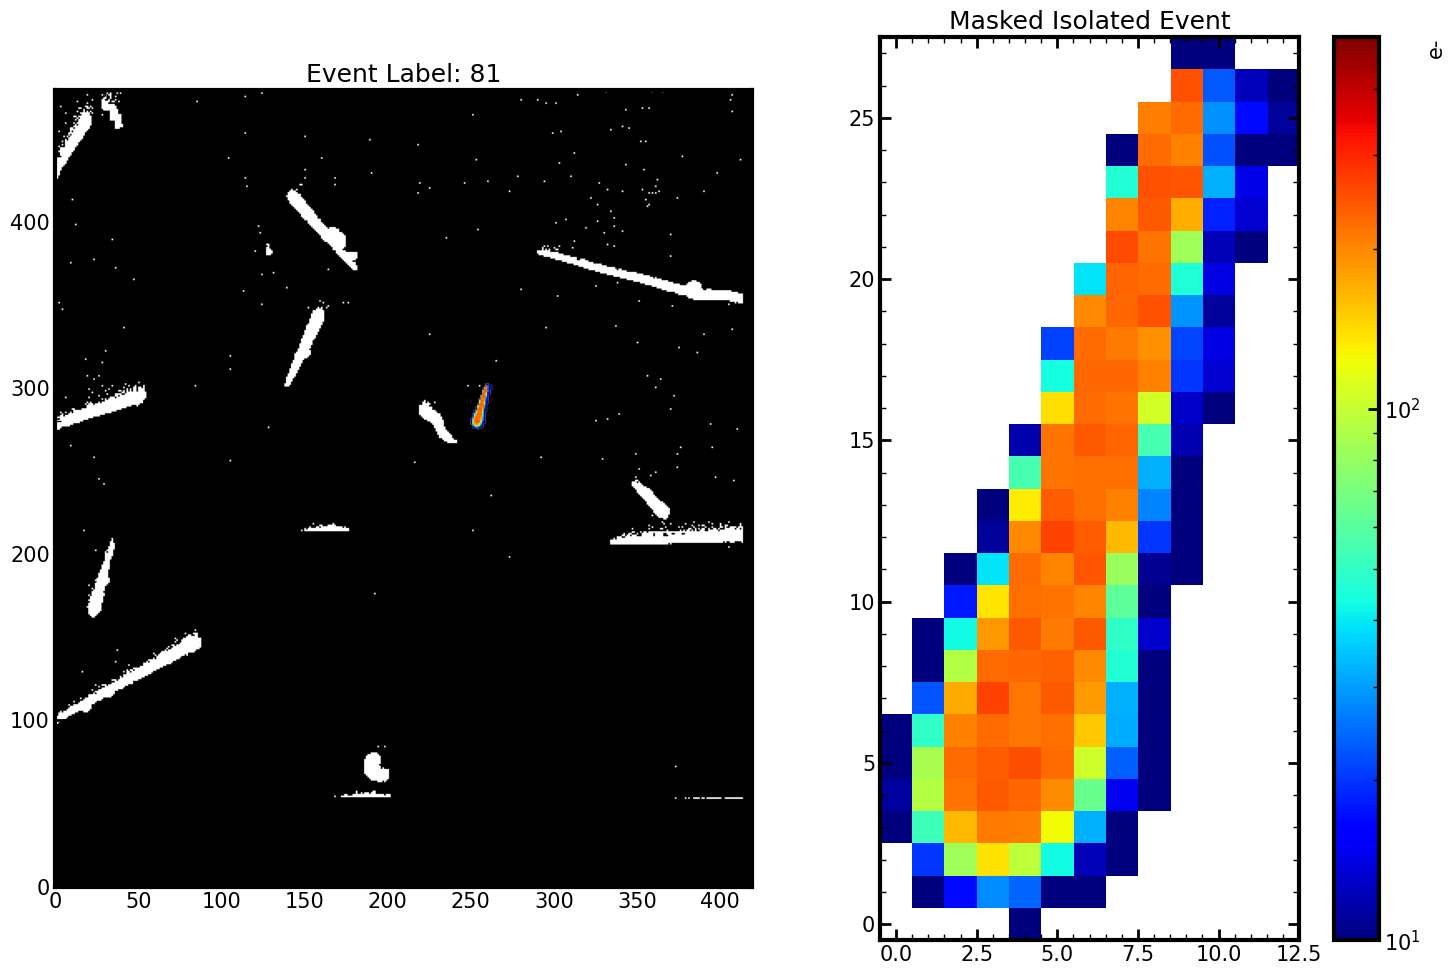

In [11]:
n_label = 81 # [4, 6, 16, 32, 36, 58, 89, 96]
extra = 0

Norm = mpl.colors.LogNorm(vmin=10**1, vmax=5 * 10**2)
label, n_events = nd.label(activeArea > min_energy_for_label,structure=[[1,1,1],[1,1,1],[1,1,1]])
loc = nd.find_objects(label==n_label)[0]

fig, axs = plt.subplots(ncols=2, nrows=1, figsize=[15,10])
# fig.subplots_adjust(left=0.1, bottom=0.1, right=0.5, top=0.9)
# fig.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9)

display(TotalDataFrame.iloc[[n_label-1]])


# fig.suptitle('Event Number '+ str(n_label))
## Imagen original
axs[0].set_title(f'Event Label: {n_label}')
axs[0].imshow(label==0, cmap='gist_yarg', vmax=1, vmin=0, origin='lower')
# plt.suptitle('Primer Imagen')

mask_35 = np.invert(label==n_label)

data_mask = ma.masked_array(activeArea[loc[0].start-extra:loc[0].stop+extra, loc[1].start-extra:loc[1].stop+extra], mask_35[loc[0].start-extra:loc[0].stop+extra, loc[1].start-extra:loc[1].stop+extra])
data_mask_all = ma.masked_array(activeArea, mask_35)
axs[0].imshow(data_mask_all, cmap= Colormap, norm=Norm)#, origin = 'lower')
print(len(data_mask[0]))

axs[1].set_title('Masked Isolated Event')
x2 = axs[1].imshow(data_mask, cmap= Colormap, norm=Norm)#, origin='lower')
# axs[1,1].plot(totalFrame.iat[n_label-1, 7][0], totalFrame.iat[n_label-1, 7][1], 'ro') ## Plot the baricentrum
# print('n_label:', n_label)
# plt.legend('Baricentrum')

fig.colorbar(x2, ax=axs[1], label = "e-")
# fig.colorbar(axs[1,1], ax=[[x1,x2]], location = 'bottom', fraction = .1)

print(f'Event Slice: x: [{loc[1].start},{loc[1].stop}], y: [{loc[0].start},{loc[0].stop}]')
# print(loc)
# print(totalFrame.set_index('Event ID').iloc[[n_label-1]])
plt.tight_layout()
plt.show()

### Con faldas

,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
61,470,10,1x1,1,1.911664,1.912,"[0.0, 0.0]"


5
Event Slice: x: [26,27], y: [245,246]


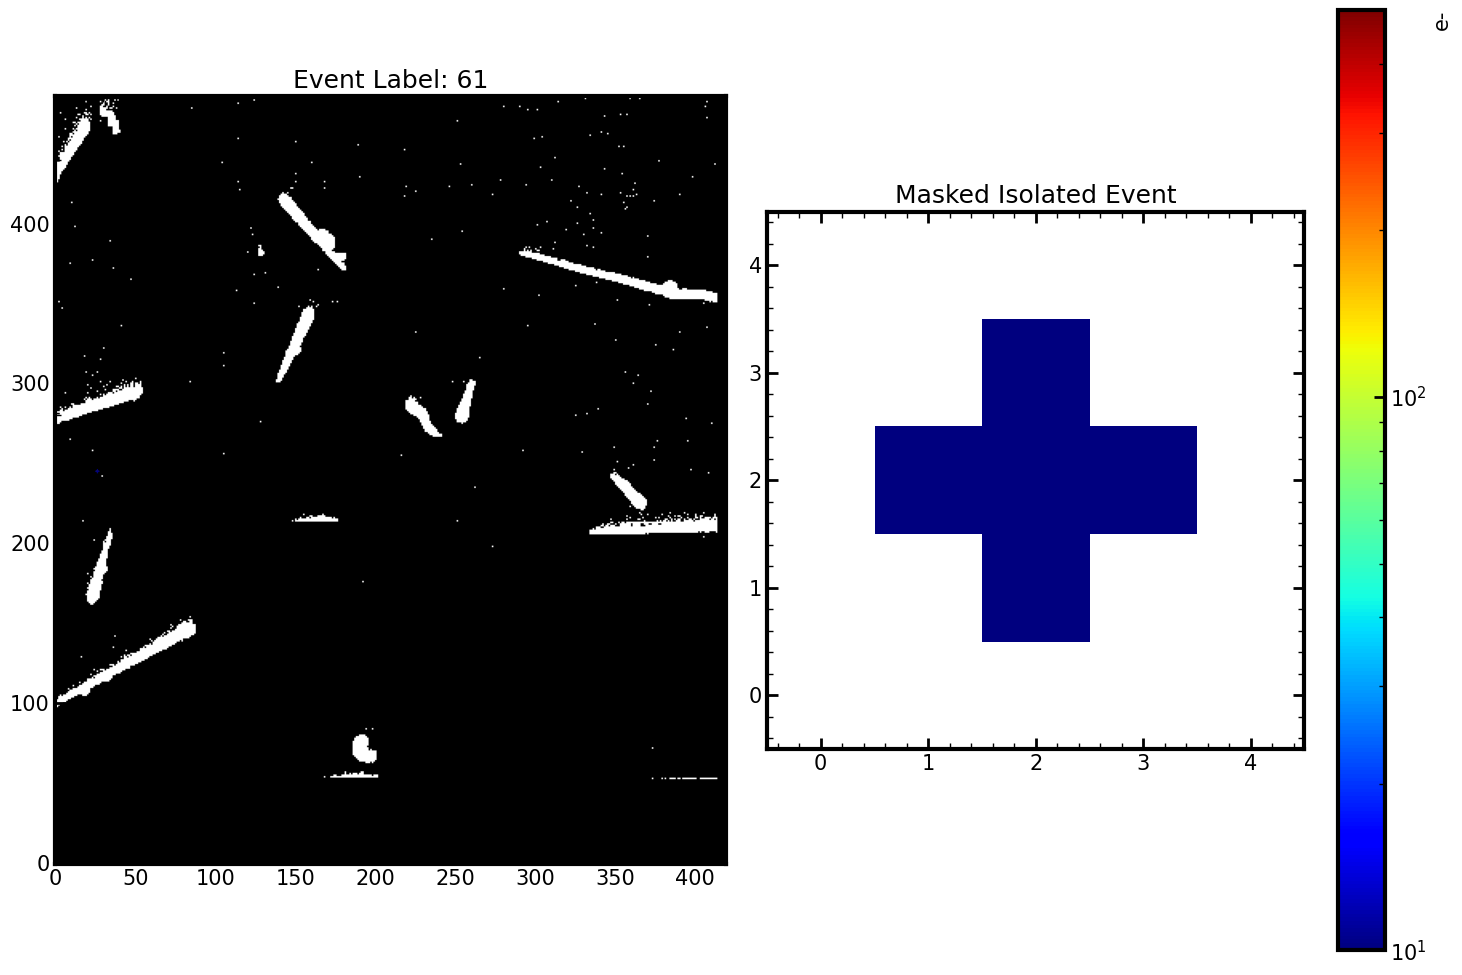

In [33]:
n_skirts = 1
extra = n_skirts+1

# label, n_events = nd.label(activeArea > min_energy_for_label,structure=[[1,1,1],[1,1,1],[1,1,1]])
# loc = nd.find_objects(label==n_label)[0]

fig, axs = plt.subplots(ncols=2, nrows=1, figsize=[15,10])
# fig.subplots_adjust(left=0.1, bottom=0.1, right=0.5, top=0.9)
# fig.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9)

display(TotalDataFrame.iloc[[n_label-1]])


# fig.suptitle('Event Number '+ str(n_label))
## Imagen original
axs[0].set_title(f'Event Label: {n_label}')
axs[0].imshow(label==0, cmap='gist_yarg', vmax=1, vmin=0, origin='lower')
# plt.suptitle('Primer Imagen')

### Skirts ###
mask_35 = np.invert(nd.binary_dilation(label==n_label, iterations= n_skirts))
# mask_35 = np.invert(label==n_label)
# skirt = nd.binary_dilation(mask_35, structure=[[0,0,0],[0,1,0],[0,0,0]], iterations = 2)
# print(skirt)

data_mask = ma.masked_array(activeArea[loc[0].start-extra:loc[0].stop+extra, loc[1].start-extra:loc[1].stop+extra], mask_35[loc[0].start-extra:loc[0].stop+extra, loc[1].start-extra:loc[1].stop+extra])
data_mask_all = ma.masked_array(activeArea, mask_35)
axs[0].imshow(data_mask_all, cmap= Colormap, norm=Norm)#, origin = 'lower')
print(len(data_mask[0]))

axs[1].set_title('Masked Isolated Event')
x2 = axs[1].imshow(data_mask, cmap= Colormap, norm=Norm)#, origin='lower')
# axs[1,1].plot(totalFrame.iat[n_label-1, 7][0], totalFrame.iat[n_label-1, 7][1], 'ro') ## Plot the baricentrum
# print('n_label:', n_label)
# plt.legend('Baricentrum')

fig.colorbar(x2, ax=axs[1], label = "e-")
# fig.colorbar(axs[1,1], ax=[[x1,x2]], location = 'bottom', fraction = .1)

print(f'Event Slice: x: [{loc[1].start},{loc[1].stop}], y: [{loc[0].start},{loc[0].stop}]')
# print(loc)
# print(totalFrame.set_index('Event ID').iloc[[n_label-1]])
plt.tight_layout()
plt.show()

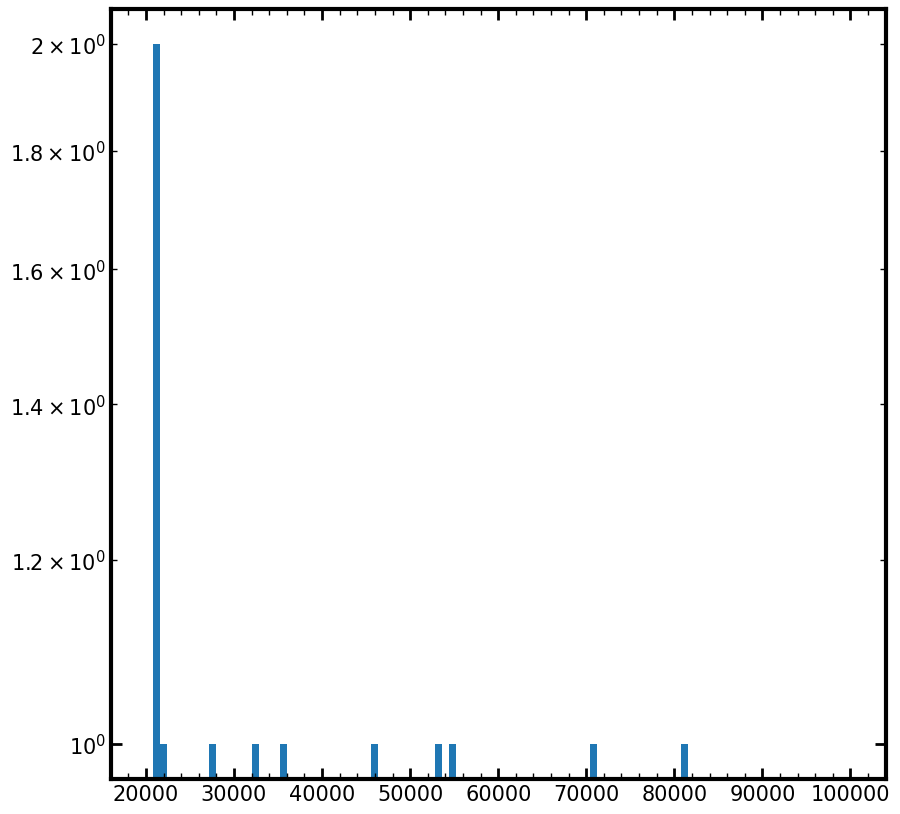

In [34]:
fig, axs = plt.subplots(figsize = [10,10])
axs.hist(TotalDataFrame["Total Charge (e-)"], bins=100,range = (20000, 100000))
axs.set_yscale("log")
plt.show()

## Filtro de Muones

Centroide:  (np.float64(287.2758620689655), np.float64(256.0689655172414))
Radio mayor: 15.421743965059521
Radio menor: 3.8902114214191577
Elipticity: 0.747745039067367
Box:  (275, 250, 303, 263)
Centroide Local:  [12.27586207  6.06896552]
Centroid Weighted:  (np.float64(nan), np.float64(nan))
Moments Hu:  [ 3.63453925e-01  1.02378339e-01  4.99355076e-03  2.85914203e-03
  1.08012448e-05  9.13578137e-04 -2.13119724e-07]
Area_Convex:  205.0
Label:  81
Orientation:  0.2912666015581287
Slice:  (slice(275, 303, None), slice(250, 263, None))
Eccentricity:  0.9676608055950576
Solidity:  0.848780487804878
Barycenter:  [12.27586207  6.06896552]
Inertia tensor:  [[  8.3745541  -15.31430836]
 [-15.31430836  54.86642885]]
Intensity Max:  266.558349609375


Event Charge:  19182.605  keV
Local Box:  [13, 28]  px
Local Box:  [195, 420] micras
Diagonal Lenght:  29.456484518493166  px
Diagonal Lenght:  441.8472677773975  micras
Delta_L:  675.6424235349556  px
Delta_L:  10134.636353024334  micras
Delta 

(np.float64(249.0), np.float64(264.0), np.float64(274.0), np.float64(304.0))

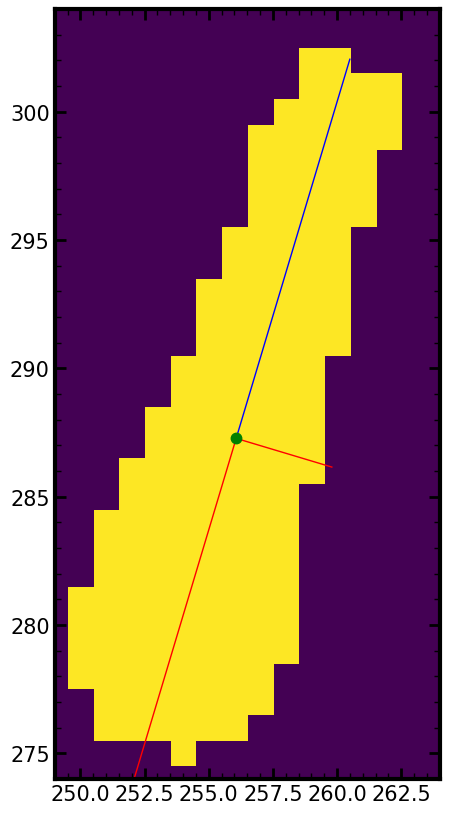

In [12]:
### Esta celda tiene el proceso para ir obteniendo las propiedadesd de un evento con la librería Scikit-Image

n_label= 81
CCD_depth = 675 ## micras
px_to_micras = 15 ## micras
px_to_cm = 0.0015 ## cm/px
micra_to_cm = 1 / 10000 ## micras/cm
fig, ax = plt.subplots(figsize=(10,10))

label_img, nlabels_img = sk.measure.label(activeArea > min_energy_for_label, connectivity=2, return_num=True)
# print(nlabels_img)
ax.imshow(label_img==n_label) # Matriz centrada en el origen

prop = sk.measure.regionprops(label_img,activeArea)
# prop = sk.measure.regionprops(label_img)


# loc = ndimage.find_objects(label==n_label)[0]
loc = prop[n_label-1].slice

mask_35 = np.invert(label_img==n_label)
# ax.imshow(dataCal[loc[0].start:loc[0].stop, loc[1].start:loc[1].stop])

data_mask = ma.masked_array(activeArea[loc[0].start:loc[0].stop, loc[1].start:loc[1].stop], mask_35[loc[0].start:loc[0].stop, loc[1].start:loc[1].stop])
charge = data_mask.sum()
# plt.imshow(dataCal[maxim.start:maxim.stop])
# ax.imshow(data_mask)


rM = prop[n_label-1].axis_major_length/2
rm = prop[n_label-1].axis_minor_length/2
elip = (rM - rm) / rM

print("Centroide: ", prop[n_label-1].centroid)
print(f"Radio mayor: {rM}")
print(f"Radio menor: {rm}")
print(f"Elipticity: {elip}")
print("Box: ", prop[n_label-1].bbox)
print("Centroide Local: ", prop[n_label-1].centroid_local)
print('Centroid Weighted: ', prop[n_label-1].centroid_weighted)
# print(prop[n_label-1].centroid_weighted_local)
# print(prop[n_label-1].coords_scaled)
# print(prop[n_label-1].coords)
# print(prop[n_label-1].extent)
# print(prop[n_label-1].image)
# print(prop[n_label-1].image_intensity)
# print('Moments: ', prop[n_label-1].moments)
# print('Moments Central: ', prop[n_label-1].moments_central)
print('Moments Hu: ', prop[n_label-1].moments_hu)
print('Area_Convex: ', prop[n_label-1].area_convex)
print('Label: ', prop[n_label-1].label)
print('Orientation: ', prop[n_label-1].orientation)
print('Slice: ', prop[n_label-1].slice)
print('Eccentricity: ', prop[n_label-1].eccentricity)
print('Solidity: ', prop[n_label-1].solidity)
print('Barycenter: ', prop[n_label-1].centroid_local)
print('Inertia tensor: ', prop[n_label-1].inertia_tensor)
print('Intensity Max: ', prop[n_label-1].intensity_max)

## Box and Delta_L
miny, minx, maxy, maxx = prop[n_label-1].bbox
Longitud_y = maxy - miny # px
Longitud_x = maxx - minx # px
Diagonal_lenght= np.sqrt(Longitud_x**2 + Longitud_y**2) - np.sqrt(2) # px
Delta_L = np.sqrt(Diagonal_lenght**2 + CCD_depth**2) # px
DeltaEL = charge / Delta_L # keV/px

print('\n')

# new_par = np.sqrt(prop[n_label-1].inertia_tensor[0][0]**2 + prop[n_label-1].inertia_tensor[1][1]**2)/Diagonal_lenght
# print("New Par: ", new_par)
## Ellipse 
y0, x0 = prop[n_label-1].centroid
# y0, x0 = prop[n_label-1].centroid_weighted

orientation = prop[n_label-1].orientation
rotation = orientation*1
x1 = x0 + math.cos(orientation) * 0.5 * prop[n_label-1].axis_minor_length
y1 = y0 - math.sin(orientation) * 0.5 * prop[n_label-1].axis_minor_length

x2 = x0 - math.sin(orientation) * 0.5 * prop[n_label-1].axis_major_length
y2 = y0 - math.cos(orientation) * 0.5 * prop[n_label-1].axis_major_length # Ellipse's major radio

x3 = x0 - math.sin(-orientation) * 0.5 * prop[n_label-1].axis_major_length
y3 = y0 + math.cos(orientation) * 0.5 * prop[n_label-1].axis_major_length # Ellipse's major radio


ax.plot((x0, x1), (y0, y1), 'r', linewidth=1)
ax.plot((x0, x3), (y0, y3), 'b', linewidth=1)
ax.plot((x0, x2), (y0, y2), 'r', linewidth=1)

ax.plot(x0, y0, '.g', markersize=15) # Ellipse's center
ax.plot(prop[n_label-1].centroid_weighted[1], prop[n_label-1].centroid_weighted[0], '.g', markersize=15)


print('Event Charge: ', charge, ' keV')
print("Local Box: ", [Longitud_x, Longitud_y], ' px' )
print("Local Box: ", [Longitud_x * px_to_micras, Longitud_y * px_to_micras], 'micras' )
print('Diagonal Lenght: ', Diagonal_lenght, ' px') ## px
print('Diagonal Lenght: ', Diagonal_lenght * px_to_micras, ' micras')
print('Delta_L: ', Delta_L, ' px')
print('Delta_L: ', Delta_L * px_to_micras, ' micras')
print('Delta EL: ', DeltaEL, ' keV/px')
print('Delta EL: ', DeltaEL / px_to_micras, ' keV/micras')
print('Delta EL: ', DeltaEL / micra_to_cm, ' keV/cm')
bx = (minx, maxx, maxx, minx, minx)
by = (miny, miny, maxy, maxy, miny)
# ax.plot(bx, by, '-b', linewidth=2.5)


# excent = prop[n_label-1].eccentricity
u= x0   #x-position of the center
v= y0    #y-position of the center
b = prop[n_label-1].axis_major_length    #radius on the x-axis
a = prop[n_label-1].axis_minor_length   #radius on the y-axis

ext=1
ax.axis((loc[1].start-ext, loc[1].stop+ext, loc[0].start-ext, loc[0].stop+ext))
# ax.imshow(data_mask)
# ax.can_zoom()

In [13]:
## Calcula cuantos eventos rectos tiene la extensión comparando la relación del radio mayor de la elipse con el radio menor
dict_lists = muon_filter(dataCal=activeArea, label_img=label_img, nlabels_img=nlabels_img, prop=prop, Solidit=0.65, Elipticity=0.3, dedl_min = 0)
DeltaL = dict_lists["muons"]["l"]
DeltaEL = dict_lists["muons"]["dedl"]
list_charge = dict_lists["muons"]["charge_muons"]
list_theta = dict_lists["muons"]["theta"]
list_phi = dict_lists["muons"]["phi"]
list_elip = dict_lists["muons"]["elip"]
list_soli = dict_lists["muons"]["sol"]
list_datamasked = dict_lists["muons"]["image"]
lebel_muons = dict_lists["muons"]["label"]

list_charge_all_events = dict_lists["non_muons"]["charge"]
list_elip_all = dict_lists["non_muons"]["elip"]
list_sol_all = dict_lists["non_muons"]["sol"]
                                                                    
print('All Clusters: ', nlabels_img)
print('Muons Detected: ', len(lebel_muons))
print(lebel_muons)
Straight_Events = lebel_muons


DF_straightevents = pd.DataFrame(lebel_muons, columns=['Event ID'] )
DF_dl = pd.DataFrame(DeltaL, columns=['Delta L (cm)'])
DF_charge = pd.DataFrame(list_charge, columns=['Charge (e-)'])
DF_dedl = pd.DataFrame(DeltaEL, columns=['dE/dL (e-/cm)'])
DF_thet = pd.DataFrame(list_theta, columns=['Theta (Rad)'])
DF_phi = pd.DataFrame(list_phi, columns=['Phi (Rad)'])
DF_elip = pd.DataFrame(list_elip, columns=['Elipticity'])
DF_soli = pd.DataFrame(list_soli, columns=['Solidity'])
DF_dEdL = pd.concat([DF_straightevents, DF_dl, DF_charge,  DF_dedl, DF_thet, DF_phi, DF_elip, DF_soli], axis=1)
DF_dEdL.set_index('Event ID')

All Clusters:  282
Muons Detected:  9
[9, 14, 28, 37, 80, 81, 107, 160, 211]


,Delta L (cm),Charge (e-),dE/dL (e-/cm),Theta (Rad),Phi (Rad),Elipticity,Solidity
Event ID,,,,,,,
9,0.080182,814.806152,10161.967565,0.570121,6.282970,0.890636,0.670103
14,0.168455,70825.281250,420441.430855,1.158514,0.513297,0.921962,0.666029
28,0.100354,32161.093750,320476.256909,0.833055,4.438207,0.846196,0.745257
37,0.077990,2022.891968,25937.706622,0.524666,6.279399,0.854735,0.772277
80,0.112864,45895.390625,406644.072007,0.929710,0.331279,0.845203,0.713004
81,0.080676,19182.605469,237774.787861,0.579594,4.459932,0.747745,0.848780
107,0.103437,35700.046875,345137.895050,0.859824,1.142750,0.853362,0.820707
160,0.068233,1395.363892,20450.096168,0.146673,3.403270,0.505850,0.826087
211,0.097984,27625.195312,281935.061453,0.810845,1.032217,0.804318,0.716667


,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
9,470,10,30x4,65,814.806152,12.535,"[15.3692, 0.7538]"


,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
14,470,10,88x56,696,70825.28125,101.760002,"[47.8218, 29.9339]"


,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
28,470,10,17x48,275,32161.09375,116.948997,"[8.1418, 19.7564]"


,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
37,470,10,27x5,78,2022.891968,25.934999,"[13.6795, 1.0897]"


,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
80,470,10,55x28,477,45895.390625,96.217003,"[28.2285, 13.9455]"


,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
81,470,10,13x28,174,19182.605469,110.245003,"[6.069, 12.2759]"


,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
107,470,10,24x48,325,35700.046875,109.846001,"[12.6308, 25.5477]"


,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
160,470,10,4x7,19,1395.363892,73.440002,"[1.1053, 2.4211]"


,Image ID,Extension,Matrix Size (px),Event Size (px),Total Charge (e-),Mean Charge (e-),Barycenter (px)
Event ID,,,,,,,
211,470,10,23x43,301,27625.195312,91.778,"[10.3056, 23.4352]"


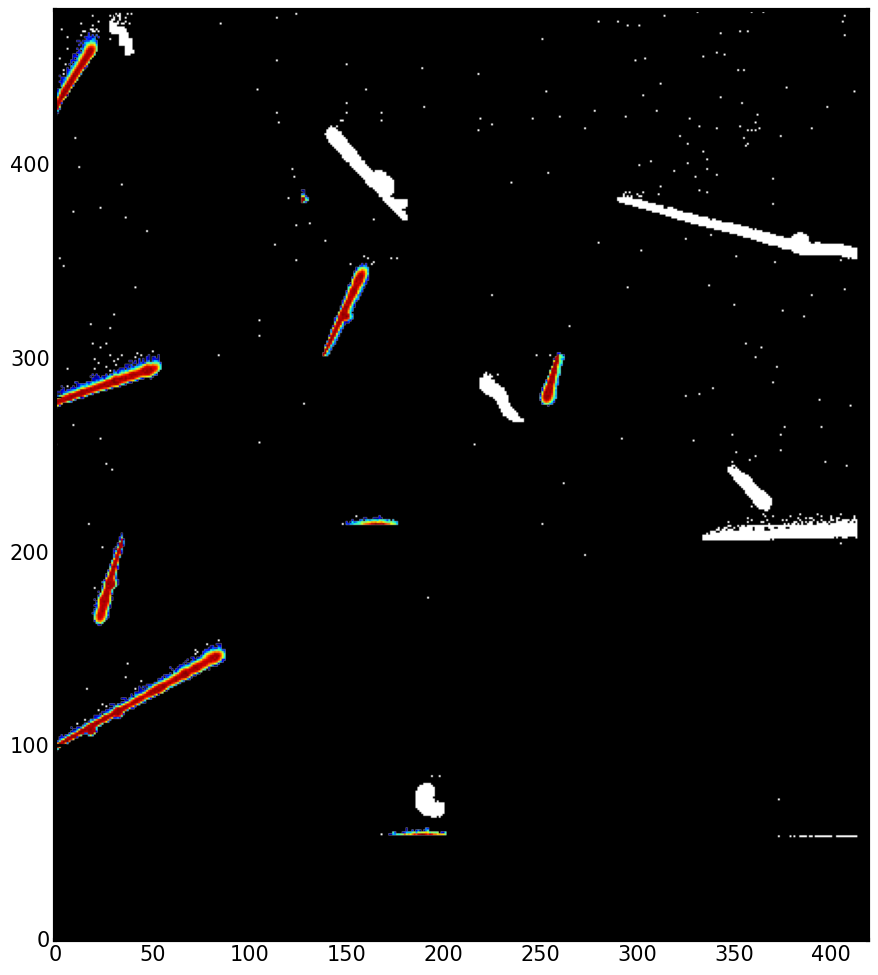

In [17]:
extra = 0

# Norm = matplotlib.colors.LogNorm(vmin=10**-2, vmax=10 * 10**0)
# label, n_events = sk.measure.label(dataCal > min_energy_for_label, connectivity=2, return_num=True)
# loc = nd.find_objects(label==n_label)[0]

fig, axs = plt.subplots(ncols=1, nrows=1, figsize=[15,10])
axs.imshow(label==0, cmap='gist_yarg', vmax=1, vmin=0, origin='lower')
# plt.suptitle('Primer Imagen')

# for n_label in (61, 150):
for n_label in lebel_muons:
    # if n_label in (9, 37, 160):
        # continue
    display(TotalDataFrame.iloc[[n_label-1]])
    mask_35 = np.invert(label==n_label)

    data_mask = ma.masked_array(activeArea[loc[0].start-extra:loc[0].stop+extra, loc[1].start-extra:loc[1].stop+extra], mask_35[loc[0].start-extra:loc[0].stop+extra, loc[1].start-extra:loc[1].stop+extra])
    data_mask_all = ma.masked_array(activeArea, mask_35)
    axs.imshow(data_mask_all, cmap= Colormap, norm=mpl.colors.LogNorm())#, origin = 'lower')


plt.tight_layout()
plt.show()

# TotalDataFrame.iloc[[n_label-1]]